# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [26]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [10]:
file = Path(rf"configuration_ELBE.toml")
uc = rp.UnitCell.from_toml(file)

## Simulation Run LOOP

In [8]:
rp.set_logging_level("ERROR")

In [22]:
sims = {}
for adr in [0.13, 201.9, 319, 1.1e5]:
    uc.beam_list.current.update_beam_param(dose_rate=adr)
    sim = uc.prepare_chunked_run([1e-9, 600], atol=1e-6, rtol=1e-5, use_jac=False)
    res = sim.run()
    sims[adr] = res.to_pandas()



  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

In [56]:
bins = np.arange(start=0, stop=df.index[-1], step=1e-3)
df.groupby(pd.cut(df["KR_7"], bins=bins)).

## Results usage

### Plot

In [17]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3

#### Water-only Radiolytic produced species

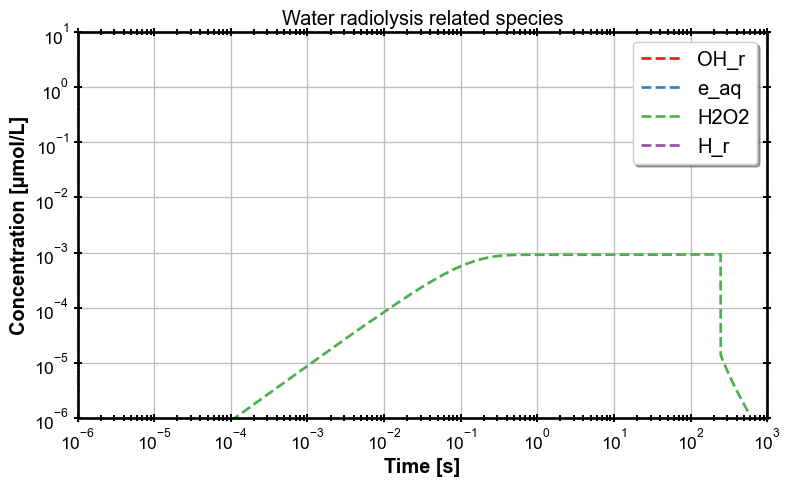

In [18]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]

with fig_man.open(f"Water radiolysis related species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=1e-6, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Water radiolysis related species")

#### Biology related species

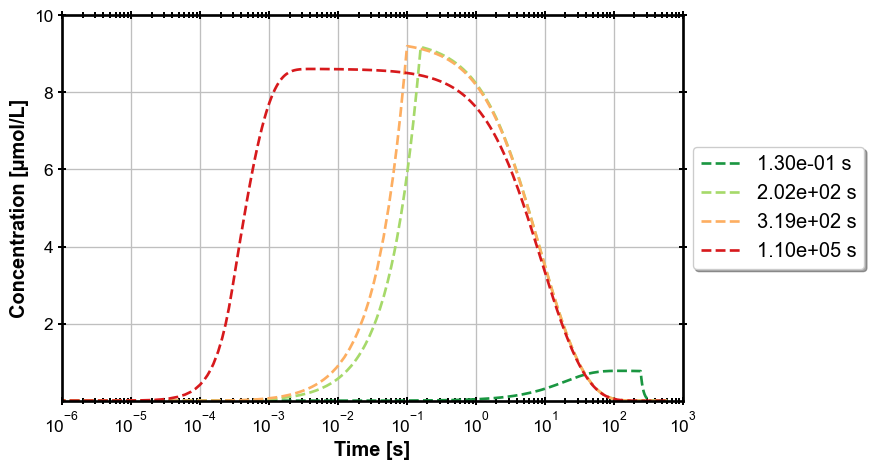

In [25]:
species = "ROO_r"
fig_man.set_brewer_map("RdYlGn", "diverging", 4, reverse=True)
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for adr, df in sims.items():
        ax.plot(df.index, df[species], label=f"{adr:.2e} s", marker="")

    ax.set_ylim(bottom=1e-6)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")
    #fig.savefig(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\BE_FLASH_CONSORTIUM\image.png", transparent=True)

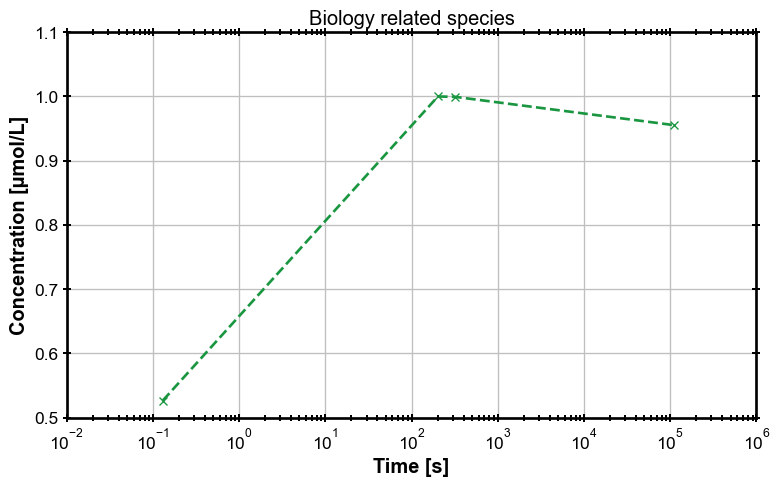

In [27]:
species = "ROO_r"
adf = pd.Series(dtype=np.float64)
for adr, df in sims.items():
    mask = np.where((df.index>=1e-4)&(df.index<100))
    adf.loc[adr] = simpson(y=df[species].values[mask].clip(min=0), x=df.index[mask])
    
with fig_man.open(f"Comparison of {species} ROO_r") as (fig, ax):
    
    ax.plot(adf.index, adf/adf.max(), marker="x")

    #ax.set_ylim(bottom=1e-6, top=2)
    ax.set_ylim([0.5, 1.1])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")

    ax.set_title("Biology related species")

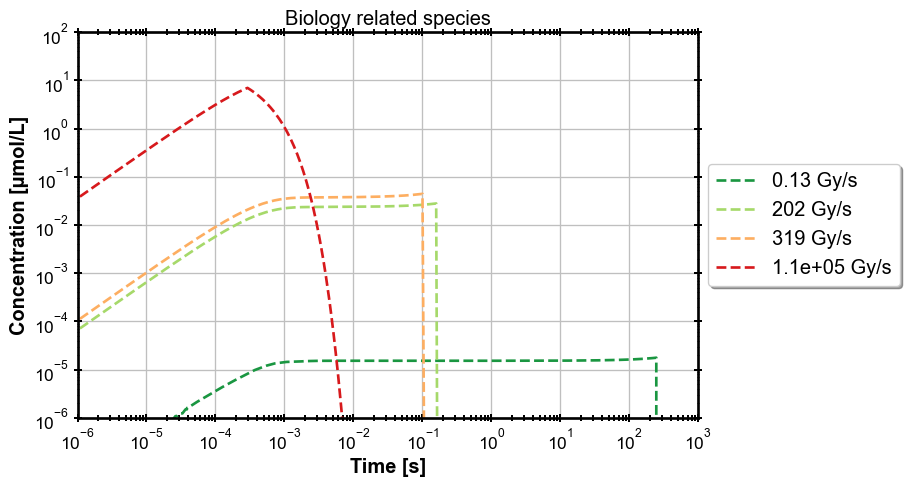

In [33]:
species = "R_r"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.3g} Gy/s", marker="")

    ax.set_ylim(bottom=1e-6, top=1e2)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

#### O2

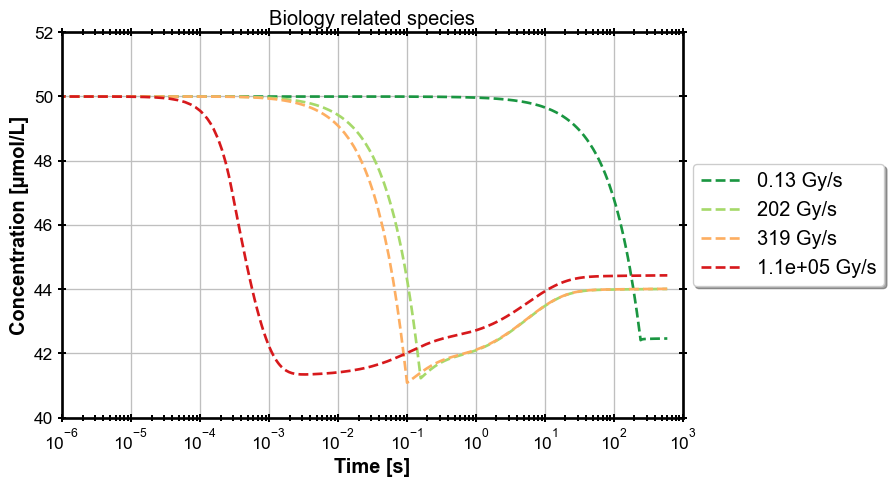

In [35]:
species = "O2"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.3g} Gy/s", marker="")

    #ax.set_ylim(bottom=45, top=50)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

## Oxygen concentration evolution

In [71]:
file = Path(rf"configuration_ELBE.toml")
uc = rp.UnitCell.from_toml(file)

In [72]:
uc.set_beam("O2_depletion")

In [73]:
uc.beam_list.current

PulsedBeam(dose_rate=4083.3333333333335, timer=Timer(period=120, on_time=0.1, start_time=0.0), max_dose=3920000.0, label='default', time_at_max_dose=840.1, dose_per_pulse=490000.0, peak_dose_rate=4900000.0)

In [77]:
0.1*4.9e6/120

4083.3333333333335

In [74]:

sim = uc.prepare_chunked_run([1e-9, 1000], atol=1e-7, rtol=1e-5, use_jac=False)
res = sim.run()
df = res.to_pandas()



  0%|          | 0/16 [00:00<?, ?it/s]

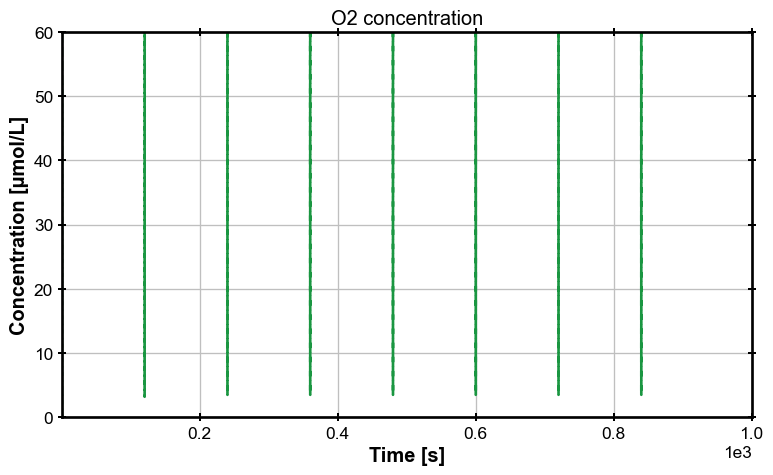

In [75]:
species = "O2"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    ax.plot(df.index, df[species], marker="")

    ax.set_ylim(bottom=0, top=60)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("O2 concentration")

In [46]:
150e-6 * 769.23 * 760

87.69221999999999

In [63]:
0.04/769.23

5.2000052000052e-05